# Контрольная работа
## Кластеризация искусственно сформированных данных

## Цель работы

Изучение алгоритмов и методов кластеризации на практике.

## 1. Определение функции создания набора данных

Используем предложенную в методичке функцию make_data.
Она формирует три группы объектов с двумя числовыми
признаками x и y.

Выберем n = 50 объектов в каждой группе и seed = 42.
Всего будет сформировано 150 объектов.
Параметр seed обеспечивает воспроизводимость данных.

In [1]:
# Настройка потоков перед подключением библиотек
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd


# Функция из методички
def make_data(n, seed):
    np.random.seed(seed)

    shift_matrix = np.array([
        [3, 3],
        [6, 9],
        [9, 3]
    ])

    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])

    df = pd.DataFrame(
        {"x": data[:, 0], "y": data[:, 1]},
        columns=["x", "y"]
    )
    df = df.sample(frac=1.0)

    return df

## 2. Получение набора данных

Создадим набор данных с параметрами n = 50 и seed = 42.
Получим 150 объектов — по 50 в каждой из трёх групп,
с двумя признаками x и y. Проверим размер таблицы и пропуски.

In [2]:
df = make_data(n=50, seed=42)

print("Размер набора данных:", df.shape)
display(df.head())

print("\nКоличество пропусков:")
print(df.isna().sum())

Размер набора данных: (150, 2)


,x,y
33,38.845781,1.240865
23,31.505036,2.282322
50,91.692585,4.625246
63,169.264842,4.089659
88,136.270344,4.076603



Количество пропусков:
x    0
y    0
dtype: int64


## 3. Стандартизация данных

Признаки x и y имеют разные масштабы. Применим StandardScaler,
чтобы привести их к сопоставимому масштабу перед кластеризацией.

После преобразования среднее каждого признака будет близко
к нулю, а стандартное отклонение - к единице.

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Первые пять записей после стандартизации:")
display(X_scaled.head())

print("Проверка стандартизации:")
display(pd.DataFrame({
    "Среднее": X_scaled.mean(),
    "Стандартное отклонение": X_scaled.std(ddof=0)
}).round(6))

Первые пять записей после стандартизации:


,x,y
33,-1.440459,-0.842663
23,-1.571984,-0.153027
50,-0.493596,1.398419
63,0.896277,1.043762
88,0.305110,1.035116


Проверка стандартизации:


,Среднее,Стандартное отклонение
x,0.0,1.0
y,-0.0,1.0


## 4. Кластеризация методом k-means для трёх кластеров

Обучим модель на стандартизированных данных с помощью
fit_predict. Метод вернёт метку кластера для каждого объекта.

Выберем n_clusters = 3. Параметр random_state = 42
обеспечивает воспроизводимость результата.
Метки 0, 1 и 2 являются условными номерами групп.

In [4]:
from sklearn.cluster import KMeans

kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

labels_3 = kmeans_3.fit_predict(X_scaled)

# Добавляем метки в отдельную копию исходной таблицы
result_3 = df.copy()
result_3["Cluster"] = labels_3

print("Первые десять объектов с метками кластеров:")
display(result_3.head(10))

print("Количество объектов в каждом кластере:")
display(
    result_3.groupby("Cluster")
    .size()
    .rename("Количество")
    .to_frame()
)

Первые десять объектов с метками кластеров:


,x,y,Cluster
33,38.845781,1.240865,2
23,31.505036,2.282322,2
50,91.692585,4.625246,0
63,169.264842,4.089659,0
88,136.270344,4.076603,0
78,121.993027,4.367672,0
87,113.558770,4.463586,0
1,57.234714,1.307459,2
72,148.055886,4.461449,0
46,50.787225,1.648060,2


Количество объектов в каждом кластере:


,Количество
Cluster,
0,50
1,50
2,50


## 5. Визуализация кластеров и их центров

Построим диаграмму рассеяния scatter. Объекты разных
кластеров обозначим разными цветами, центры - крестиками.

График построим в исходных единицах признаков x и y.
Для этого преобразуем центры из стандартизированного
масштаба обратно с помощью inverse_transform.

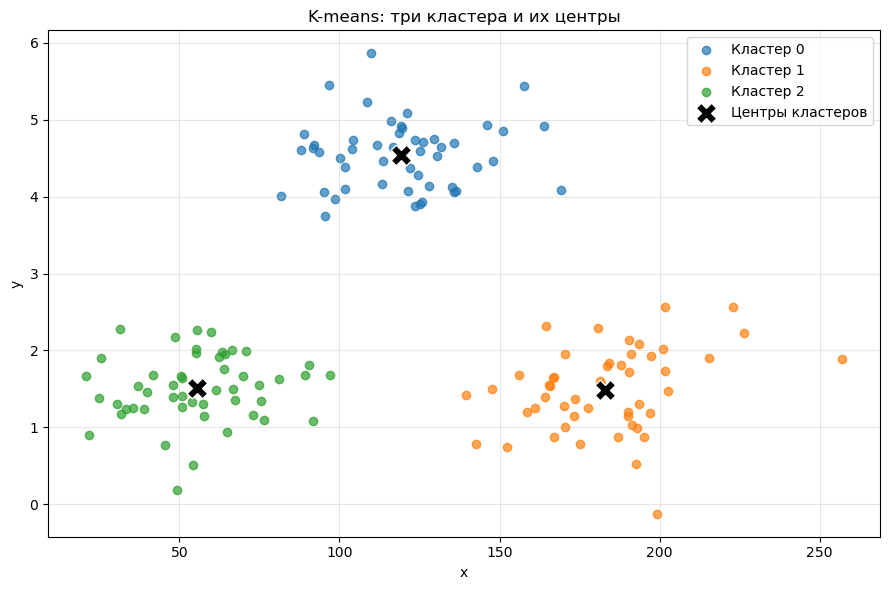

In [5]:
import matplotlib.pyplot as plt

# Возвращаем центры в исходный масштаб признаков
centers_3 = scaler.inverse_transform(
    kmeans_3.cluster_centers_
)

colors = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(9, 6))

for cluster in range(3):
    mask = labels_3 == cluster

    plt.scatter(
        df.loc[mask, "x"],
        df.loc[mask, "y"],
        color=colors[cluster],
        label=f"Кластер {cluster}",
        alpha=0.7
    )

plt.scatter(
    centers_3[:, 0],
    centers_3[:, 1],
    color="black",
    marker="X",
    s=220,
    label="Центры кластеров",
    edgecolors="white"
)

plt.title("K-means: три кластера и их центры")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На диаграмме видны три хорошо разделённых кластера
по 50 объектов. Центры располагаются внутри соответствующих
групп. Визуально разбиение на три кластера соответствует
структуре сформированных данных.

## 6. Определение кластеров для тестовых данных

Создадим отдельный набор test той же функцией make_data,
используя другое зерно случайных чисел seed = 24.

Преобразуем тестовые данные ранее обученным StandardScaler.
С помощью predict определим принадлежность новых объектов
к кластерам без повторного обучения модели.
Построим график с центрами, полученными на обучающих данных.

Первые десять тестовых объектов с метками:


,x,y,Cluster
17,81.154749,0.887538,2
95,142.906049,4.592600,0
1,44.599331,2.030665,2
75,123.001568,4.781802,0
35,18.212914,2.176893,2
114,177.398864,2.442263,1
23,58.733440,1.333111,2
33,33.480737,1.829240,2
2,53.674393,1.847902,2
130,180.388838,2.319789,1


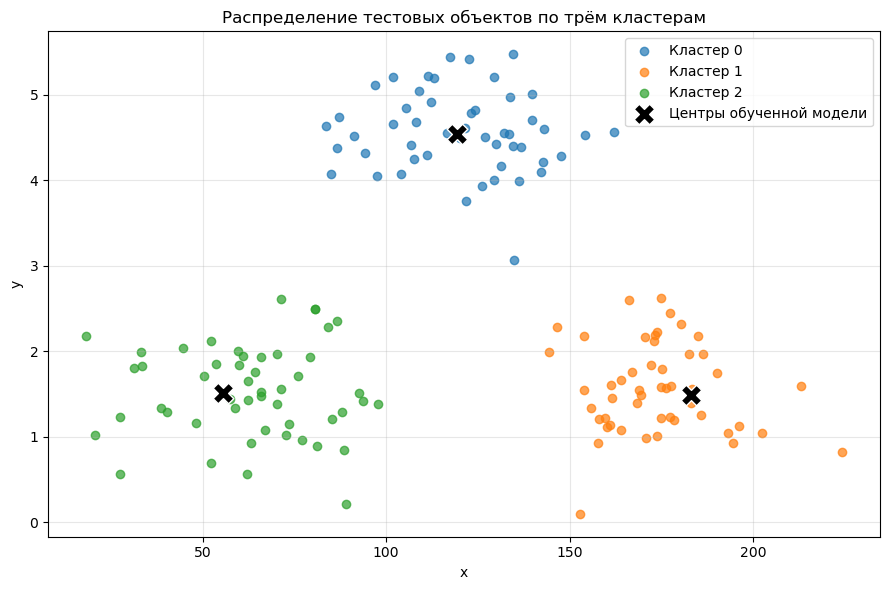

In [6]:
# Создаём новые данные
test = make_data(n=50, seed=24)

# Используем уже обученный стандартизатор
test_scaled = scaler.transform(test)

# Определяем кластеры без повторного обучения
test_labels_3 = kmeans_3.predict(
    pd.DataFrame(
        test_scaled,
        columns=df.columns,
        index=test.index
    )
)

test_result_3 = test.copy()
test_result_3["Cluster"] = test_labels_3

print("Первые десять тестовых объектов с метками:")
display(test_result_3.head(10))

plt.figure(figsize=(9, 6))

for cluster in range(3):
    mask = test_labels_3 == cluster

    plt.scatter(
        test.loc[mask, "x"],
        test.loc[mask, "y"],
        color=colors[cluster],
        label=f"Кластер {cluster}",
        alpha=0.7
    )

plt.scatter(
    centers_3[:, 0],
    centers_3[:, 1],
    color="black",
    marker="X",
    s=220,
    label="Центры обученной модели",
    edgecolors="white"
)

plt.title("Распределение тестовых объектов по трём кластерам")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Тестовые объекты образуют три визуально разделённые группы.
Модель распределила новые наблюдения по кластерам без
повторного обучения. Центры, найденные на исходных данных,
располагаются вблизи центральных областей тестовых групп.

## 7. Вычисление коэффициента силуэта

Вычислим коэффициент силуэта на стандартизированных данных.
Он характеризует близость объекта к своему кластеру
по сравнению с другими кластерами.

Значения ближе к 1 соответствуют хорошо разделённым
компактным группам, около 0 - пересекающимся группам,
отрицательные значения указывают на возможное отнесение
объекта к неподходящему кластеру.

Отдельно оценим исходные и тестовые данные.

In [7]:
from sklearn.metrics import silhouette_score

silhouette_train_3 = silhouette_score(
    X_scaled, labels_3
)

silhouette_test_3 = silhouette_score(
    test_scaled, test_labels_3
)

silhouette_results_3 = pd.DataFrame({
    "Набор данных": ["Исходный", "Тестовый"],
    "Количество кластеров": [3, 3],
    "Коэффициент силуэта": [
        silhouette_train_3,
        silhouette_test_3
    ]
})

display(silhouette_results_3.round(4))

,Набор данных,Количество кластеров,Коэффициент силуэта
0,Исходный,3,0.7242
1,Тестовый,3,0.7019


При трёх кластерах коэффициент силуэта составил 0,7242
на исходных данных и 0,7019 на тестовых. Полученные значения
согласуются с визуально выраженным разделением групп.

## 8. Сравнение разбиений на два, три и четыре кластера

Повторим обучение методом fit_predict для двух и четырёх
кластеров. Для каждой модели получим метки тестовых объектов
с помощью predict, построим диаграммы с центрами кластеров
и вычислим коэффициенты силуэта.

Стандартизатор и наборы данных оставим прежними,
чтобы сравнивать модели в одинаковых условиях.

Метки первых 10 исходных объектов, k = 2:
[0 0 1 1 1 1 1 0 1 0]
Метки первых 10 тестовых объектов, k = 2:
[0 1 0 1 0 0 0 0 0 0]


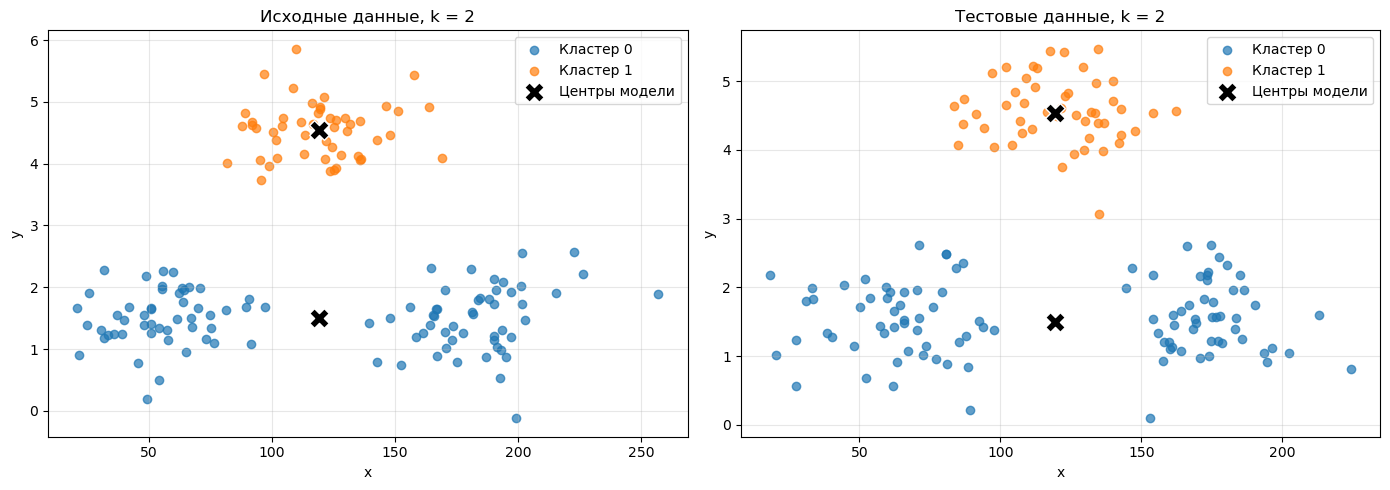

Метки первых 10 исходных объектов, k = 4:
[1 1 2 2 2 2 2 1 2 1]
Метки первых 10 тестовых объектов, k = 4:
[1 2 1 2 1 0 1 1 1 0]


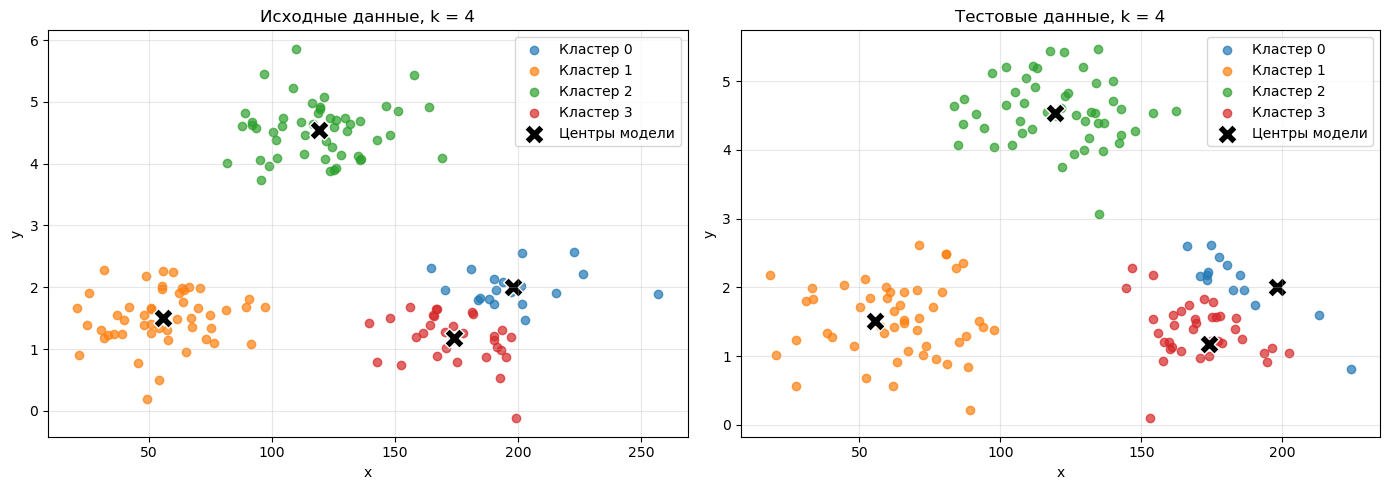

Сравнение коэффициентов силуэта:


,Количество кластеров,Силуэт исходных данных,Силуэт тестовых данных
0,2,0.4989,0.5170
1,3,0.7242,0.7019
2,4,0.6105,0.5665


In [8]:
# Сохраняем результат ранее обученной модели с тремя кластерами
comparison_rows = [{
    "Количество кластеров": 3,
    "Силуэт исходных данных": silhouette_train_3,
    "Силуэт тестовых данных": silhouette_test_3
}]

models = {3: kmeans_3}
train_labels = {3: labels_3}
test_labels = {3: test_labels_3}

cluster_colors = [
    "tab:blue", "tab:orange", "tab:green", "tab:red"
]

for k in [2, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    # Обучение и метки исходных объектов
    labels = model.fit_predict(X_scaled)

    # Метки новых объектов без повторного обучения
    predicted = model.predict(
        pd.DataFrame(
            test_scaled,
            columns=df.columns,
            index=test.index
        )
    )

    models[k] = model
    train_labels[k] = labels
    test_labels[k] = predicted

    comparison_rows.append({
        "Количество кластеров": k,
        "Силуэт исходных данных": silhouette_score(
            X_scaled, labels
        ),
        "Силуэт тестовых данных": silhouette_score(
            test_scaled, predicted
        )
    })

    print(f"Метки первых 10 исходных объектов, k = {k}:")
    print(labels[:10])

    print(f"Метки первых 10 тестовых объектов, k = {k}:")
    print(predicted[:10])

    centers = scaler.inverse_transform(
        model.cluster_centers_
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, data, cluster_labels, title in [
        (axes[0], df, labels, "Исходные данные"),
        (axes[1], test, predicted, "Тестовые данные")
    ]:
        for cluster in range(k):
            mask = cluster_labels == cluster

            ax.scatter(
                data.loc[mask, "x"],
                data.loc[mask, "y"],
                color=cluster_colors[cluster],
                label=f"Кластер {cluster}",
                alpha=0.7
            )

        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            color="black",
            marker="X",
            s=200,
            edgecolors="white",
            label="Центры модели"
        )

        ax.set_title(f"{title}, k = {k}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Количество кластеров")
    .reset_index(drop=True)
)

print("Сравнение коэффициентов силуэта:")
display(comparison.round(4))

При двух кластерах две нижние группы объединяются в одну,
хотя между ними заметен промежуток. Коэффициенты силуэта
составили 0,4989 на исходных данных и 0,5170 на тестовых.

При трёх кластерах получены максимальные значения силуэта:
0,7242 и 0,7019 соответственно. Разбиение соответствует
трём группам, заданным при генерации данных.

При четырёх кластерах правая нижняя группа дополнительно
разделяется на две части. Силуэт снижается до 0,6105
на исходных данных и 0,5665 на тестовых.

Таким образом, среди проверенных вариантов предпочтительным
является разбиение на три кластера.

## 9. Необходимость разделения данных на train и test

Для кластеризации разделение на обучающую и тестовую
выборки не является обязательным. Если задача заключается
в изучении структуры имеющегося набора данных, модель
можно обучать на всём наборе и оценивать полученное
разбиение с помощью внутренних метрик.

Если предполагается распределять новые объекты по ранее
найденным кластерам, отдельная тестовая выборка полезна
для проверки работы модели на новых наблюдениях.

В данной работе исходный набор не разделялся.
Вместо этого тестовый набор был независимо сформирован
той же функцией с другим seed. Стандартизатор и модель
обучались только на исходных данных. Для тестового набора
использовались transform и predict без повторного обучения.

Коэффициент силуэта на тестовых данных характеризует
компактность и разделённость полученных групп,
но не является точностью классификации.

## 10. Выбор количества кластеров методом локтя

Обучим модели k-means с количеством кластеров от 1 до 10
и вычислим инерцию - сумму квадратов расстояний объектов
до центров соответствующих кластеров.

Построим график зависимости инерции от количества кластеров.
Будем искать перегиб, после которого увеличение количества
кластеров приводит к сравнительно небольшому снижению инерции.

,Количество кластеров,Инерция
0,1,300.0000
1,2,164.6739
2,3,34.1445
3,4,28.2759
4,5,23.9909
5,6,19.9616
6,7,17.6319
7,8,15.7282
8,9,14.0537
9,10,12.3285


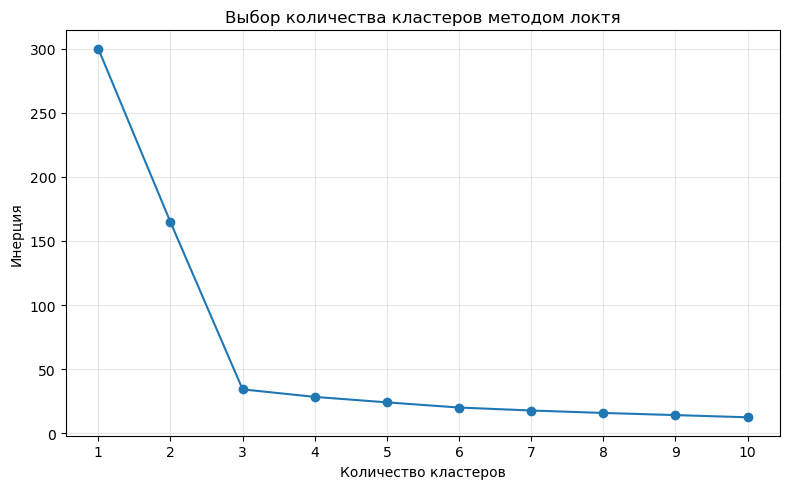

In [9]:
elbow_rows = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)

    elbow_rows.append({
        "Количество кластеров": k,
        "Инерция": model.inertia_
    })

elbow_results = pd.DataFrame(elbow_rows)

display(elbow_results.round(4))

plt.figure(figsize=(8, 5))

plt.plot(
    elbow_results["Количество кластеров"],
    elbow_results["Инерция"],
    marker="o"
)

plt.title("Выбор количества кластеров методом локтя")
plt.xlabel("Количество кластеров")
plt.ylabel("Инерция")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

При увеличении количества кластеров с двух до трёх инерция
снижается со 164,6739 до 34,1445. При переходе от трёх
к четырём кластерам снижение значительно меньше:
с 34,1445 до 28,2759.

На графике наблюдается выраженный перегиб при k = 3.
Следовательно, метод локтя подтверждает выбор трёх кластеров,
ранее обоснованный коэффициентом силуэта и визуализацией.

## Выводы по работе

В контрольной работе изучен и применён метод кластеризации
k-means. С помощью предложенной функции создан набор
из 150 объектов с двумя признаками и тремя исходными группами.
Перед обучением выполнена стандартизация StandardScaler.

Для трёх кластеров модель обучена методом fit_predict.
Получены три группы по 50 объектов. На диаграммах рассеяния
объекты выделены разными цветами, отмечены центры кластеров.

Для проверки работы модели на новых наблюдениях создан
отдельный тестовый набор из 150 объектов с другим seed.
Применены ранее обученный стандартизатор и метод predict.
Повторное обучение на тестовых данных не проводилось.

Выполнено сравнение моделей с двумя, тремя и четырьмя
кластерами. Наибольший коэффициент силуэта получен
при трёх кластерах: 0,7242 на исходных данных
и 0,7019 на тестовых. При двух кластерах две отдельные
группы объединяются, а при четырёх одна группа
дополнительно разделяется на две части.

Метод локтя также указывает на три кластера:
после k = 3 снижение инерции существенно замедляется.
Таким образом, визуализация и оба критерия выбора
согласованно подтверждают разбиение на три кластера.

Разделение данных на train и test для изучения структуры
фиксированного набора не обязательно. Однако отдельный
тестовый набор полезен, если модель должна распределять
новые объекты по уже найденным кластерам.

Цель работы достигнута: выполнены обучение модели,
визуализация кластеров, распределение новых объектов,
оценка качества и обоснование количества кластеров.